## Loading data from csv file : 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
file_path = '3D_PrA-_IndProf-NanoBlitz-VR1.xlsx'
sheet_name = 'Test 1'
data = pd.read_excel(file_path, sheet_name=sheet_name,header=0,skiprows=[1])
data = data.drop(data.columns[[0, 1]], axis=1)

display(data)

,X Position,Y Position,MODULUS,HARDNESS
0,0.000000,10.763250,1.645402,0.079737
1,0.000000,9.572625,1.797390,0.088518
2,0.000000,8.382000,1.861923,0.092811
3,0.000000,7.191375,1.856298,0.098128
4,0.000000,5.953125,1.758753,0.088199
...,...,...,...,...
995,396.001875,4.762500,1.911077,0.095792
996,396.001875,3.571875,1.704882,0.083655
997,396.001875,2.381250,1.658139,0.080182
998,396.001875,1.190625,1.761177,0.091531


## Analysing the data

#### Correlation matrix

              X Position    Y Position   MODULUS  HARDNESS
X Position  1.000000e+00  2.993834e-16 -0.066162 -0.172692
Y Position  2.993834e-16  1.000000e+00 -0.008252  0.042558
MODULUS    -6.616229e-02 -8.252438e-03  1.000000  0.805809
HARDNESS   -1.726919e-01  4.255788e-02  0.805809  1.000000


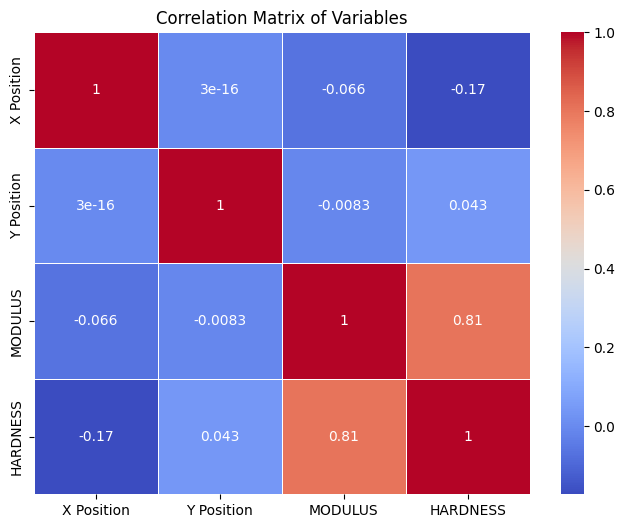

In [4]:
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')
correlation_matrix = data.corr()
print(correlation_matrix)
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Variables')
plt.show()


#### Pairplot of all numerical variables :

In [29]:
# Scatter plot of HARDNESS vs. MODULUS of Polypropylene
# Distribution of each feature in the dataset

In [ ]:
sns.pairplot(data)
plt.suptitle('Pairplot of Polypropylene Characteristics', y=1.02)
plt.show()

In [ ]:
#MODULUS : values cluster around a mean ==> normal distribution 
#HARDNESS : values are more spread out ==> not normal distribution

#### Boxplot of HARDNESS & Modulus

In [30]:
# Interquartile range and mean 

In [ ]:
# Box plot of MODULUS
plt.figure(figsize=(8,6))
sns.boxplot(x=data['MODULUS'], color='lightblue')
plt.title('Boxplot of MODULUS')
plt.show()

# Box plot of HARDNESS
plt.figure(figsize=(8,6))
sns.boxplot(x=data['HARDNESS'], color='lightgreen')
plt.title('Boxplot of HARDNESS')
plt.show()

In [9]:
#The average elasticity is around 1.75 , with few outliers 
# The median hardness is around 0.09, with some outliers above 0.12

In [ ]:
from matplotlib.colors import LogNorm
import seaborn as sns
import matplotlib.pyplot as plt

# Create pivot for Elastic modulus based on positions
dFMatPivot_E = data.pivot(index='Y Position', columns='X Position', values='MODULUS')

# Customize the z-scale
vmin = dFMatPivot_E.min().min()  # Minimum value for the z-scale
vmax = dFMatPivot_E.max().max()  # Maximum value for the z-scale

# Plot the pivot heatmap with logarithmic z-scale and equal aspect ratio
plt.figure(figsize=(10, 8))
ax = sns.heatmap(dFMatPivot_E, cmap='viridis', norm=LogNorm(vmin=vmin, vmax=vmax))
ax.set_aspect('equal', adjustable='box')
plt.title("Heatmap of Young's Modulus based on Positions")
plt.show()

In [ ]:
# Create pivot for Elastic modulus based on positions
dFMatPivot_E = data.pivot(index='Y Position', columns='X Position', values='HARDNESS')

# Customize the z-scale
vmin = dFMatPivot_E.min().min()  # Minimum value for the z-scale
vmax = dFMatPivot_E.max().max()  # Maximum value for the z-scale

# Plot the pivot heatmap with logarithmic z-scale and equal aspect ratio
plt.figure(figsize=(10, 8))
ax = sns.heatmap(dFMatPivot_E, cmap='viridis', norm=LogNorm(vmin=vmin, vmax=vmax))
ax.set_aspect('equal', adjustable='box')
plt.title("Heatmap of Hardness based on Positions")
plt.show()

#### K-means clustering and Gaussian mixture models : 

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

dfCluster=data[["HARDNESS", "MODULUS"]]

inerties = []
K_range = range(1, 11)  
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42).fit(dfCluster)
    inerties.append(kmeans.inertia_)

plt.plot(K_range, inerties, 'bx-')
plt.xlabel('Clusters number (k)')
plt.ylabel('Inertie')
plt.title('Elbow Method to Determine Optimal k')
plt.show()

In [ ]:
# Importing Modules
from sklearn import datasets
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
numComp = 2
random_stateVal = 42
sizePnt = 50
sizeMean = 100
alphaVal = 0.5
cmapVal = 'viridis'
colorMean = 'red'
markerSym = '+'

dfCluster=data[["HARDNESS", "MODULUS"]]
kmeans = KMeans(n_clusters=numComp, random_state=random_stateVal).fit(dfCluster)
y_pred = kmeans.predict(dfCluster)
centroids = kmeans.cluster_centers_
print(centroids)

# Plot the data points with color-coded clusters
plt.scatter(data['HARDNESS'], data['MODULUS'], c=y_pred, s=sizePnt, alpha=alphaVal, cmap=cmapVal) #kmeans.labels_.astype(float)
plt.colorbar()

# Plot the K-means centroids
plt.scatter(centroids[:, 0], centroids[:, 1], c=colorMean, marker=markerSym, s=sizeMean, label='K-Means')

plt.xlabel('Hardness')
plt.ylabel('Modulus')
plt.savefig('ClusterAnalysis.png', bbox_inches='tight')
plt.savefig('ClusterAnalysis.pdf', bbox_inches='tight')
plt.legend(loc='best')
plt.savefig('K-means.jpg')
plt.show()

#### Gaussian clustering analysis

In [ ]:
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

bic_scores = []
K_range = range(1, 11) 

for k in K_range:
    gmm = GaussianMixture(n_components=k, random_state=42).fit(dfCluster)
    bic_scores.append(gmm.bic(dfCluster))

plt.plot(K_range, bic_scores, 'bx-')
plt.xlabel('Number of Gaussian Components (k)')
plt.ylabel('BIC Score')
plt.title('BIC to Determine Optimal Number of Gaussian Components')
plt.show()


In [28]:
# The optimal number of Gaussian components is 2 because the BIC decreases at 2 and then increases at 3.

In [ ]:
from sklearn.mixture import GaussianMixture
numGauss = 3
dfCluster=data[["HARDNESS", "MODULUS"]]

# Create and fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=numGauss, random_state=random_stateVal)
gmm.fit(dfCluster)

# Predict cluster assignments for each data point
y_pred = gmm.predict(dfCluster)

# Get the means and covariances of the Gaussian components
means = gmm.means_
print(means)
covariances = gmm.covariances_

# Plot the data points with color-coded clusters
plt.scatter(dfCluster['HARDNESS'], dfCluster['MODULUS'], c=y_pred, s=sizePnt, alpha=alphaVal, cmap=cmapVal)
plt.colorbar()

# Plot the Gaussian component means
plt.scatter(means[:, 0], means[:, 1], c=colorMean, marker=markerSym, s=sizeMean, label='Gaussian Means')

plt.xlabel('Hardness (GPa)')
plt.ylabel('Elastic modulus (GPa)')
#plt.title('Gaussian Mixture Model')
plt.legend(loc='best')
plt.savefig('GMM.jpg')
plt.show()

#### Importing results to Granta MI

In [ ]:
import pandas as pd 
# K-means centroids
kmeans_centroids = pd.DataFrame(kmeans.cluster_centers_, columns=['K-means Centroid X', 'K-means Centroid Y'])

# K-means cluster labels (predictions)
kmeans_labels = pd.DataFrame({'K-means Cluster Label': y_pred})

print(kmeans_centroids.head())
print(kmeans_labels.head())
